# EfficientNet-B0 Evaluation

Evaluate the already trained EfficientNet-B0 checkpoint on the held-out test split using the existing class mapping and deterministic test preprocessing. No training augmentation is applied to the test images.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from torch import nn
from torchvision.models import efficientnet_b0

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset import SorghumDataset, load_class_to_idx, make_loader
from src.preprocessing import get_test_transform

In [2]:
RESULTS_DIR = PROJECT_ROOT / 'results'
MODELS_DIR = PROJECT_ROOT / 'models'
TEST_MANIFEST = RESULTS_DIR / 'test.csv'
CLASS_MAPPING = RESULTS_DIR / 'class_to_index.json'
CHECKPOINT_PATH = MODELS_DIR / 'efficientnet_b0_best.pth'
IMAGE_DIR = PROJECT_ROOT.parent / 'Dataset'
METRICS_PATH = RESULTS_DIR / 'efficientnet_b0_test_metrics.json'
CONFUSION_MATRIX_PATH = RESULTS_DIR / 'efficientnet_b0_confusion_matrix.png'
BATCH_SIZE = 32
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f'Project root: {PROJECT_ROOT}')
print(f'Device: {DEVICE}')

Project root: c:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water
Device: cuda


In [3]:
class_to_idx = load_class_to_idx(CLASS_MAPPING)
idx_to_class = {index: cultivar for cultivar, index in class_to_idx.items()}
num_classes = len(class_to_idx)
print(f'Loaded {num_classes} classes from {CLASS_MAPPING.name}.')

test_manifest = pd.read_csv(TEST_MANIFEST)
if not set(test_manifest['cultivar'].unique()).issubset(class_to_idx):
    raise ValueError('Test manifest contains cultivars absent from the existing class mapping.')

test_dataset = SorghumDataset(test_manifest, IMAGE_DIR, get_test_transform(), class_to_idx)
test_loader = make_loader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
print(f'Loaded {len(test_dataset)} test images with deterministic test preprocessing.')

Loaded 100 classes from class_to_index.json.
Loaded 500 test images with deterministic test preprocessing.


In [4]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
checkpoint_num_classes = checkpoint.get('num_classes', num_classes)
if checkpoint_num_classes != num_classes:
    raise ValueError(f'Checkpoint has {checkpoint_num_classes} classes, but the existing mapping has {num_classes}.')

model = efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(DEVICE)
model.eval()
print(f'Loaded EfficientNet-B0 checkpoint from {CHECKPOINT_PATH.name}.')

Loaded EfficientNet-B0 checkpoint from efficientnet_b0_best.pth.


In [5]:
true_labels = []
predicted_labels = []
top5_correct = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(DEVICE))
        top5_predictions = outputs.topk(min(5, num_classes), dim=1).indices.cpu()
        top5_correct += top5_predictions.eq(labels.unsqueeze(1)).any(dim=1).sum().item()
        predicted_labels.extend(outputs.argmax(dim=1).cpu().tolist())
        true_labels.extend(labels.tolist())

print(f'Inference complete for {len(true_labels)} images.')

Inference complete for 500 images.


In [6]:
test_accuracy = accuracy_score(true_labels, predicted_labels)
precision = precision_score(true_labels, predicted_labels, average='macro', zero_division=0)
recall = recall_score(true_labels, predicted_labels, average='macro', zero_division=0)
f1 = f1_score(true_labels, predicted_labels, average='macro', zero_division=0)
top5_accuracy = top5_correct / len(true_labels)

metrics = {
    'test_accuracy': test_accuracy,
    'precision': precision,
    'recall': recall,
    'f1_score': f1,
    'top5_accuracy': top5_accuracy,
}

pd.DataFrame.from_dict(metrics, orient='index', columns=['value']).rename_axis('metric')

,value
metric,
test_accuracy,0.742000
precision,0.779000
recall,0.742000
f1_score,0.737577
top5_accuracy,0.928000


In [7]:
print(f'Test accuracy: {test_accuracy:.6f}')
print(f'Precision: {precision:.6f}')
print(f'Recall: {recall:.6f}')
print(f'F1-score: {f1:.6f}')
print(f'Top-5 accuracy: {top5_accuracy:.6f}')

Test accuracy: 0.742000
Precision: 0.779000
Recall: 0.742000
F1-score: 0.737577
Top-5 accuracy: 0.928000


In [8]:
report = classification_report(
    true_labels,
    predicted_labels,
    labels=list(range(num_classes)),
    target_names=[idx_to_class[index] for index in range(num_classes)],
    zero_division=0,
)
print(report)

              precision    recall  f1-score   support

   PI_144134       0.60      0.60      0.60         5
   PI_145619       0.75      0.60      0.67         5
   PI_145626       0.60      0.60      0.60         5
   PI_145633       0.83      1.00      0.91         5
   PI_146890       0.50      1.00      0.67         5
   PI_152591       0.75      0.60      0.67         5
   PI_152651       1.00      1.00      1.00         5
   PI_152694       0.80      0.80      0.80         5
   PI_152727       0.71      1.00      0.83         5
   PI_152728       0.71      1.00      0.83         5
   PI_152730       0.33      0.20      0.25         5
   PI_152733       0.57      0.80      0.67         5
   PI_152751       1.00      0.60      0.75         5
   PI_152771       0.75      0.60      0.67         5
   PI_152816       1.00      1.00      1.00         5
   PI_152828       0.57      0.80      0.67         5
   PI_152860       0.80      0.80      0.80         5
   PI_152862       0.67    

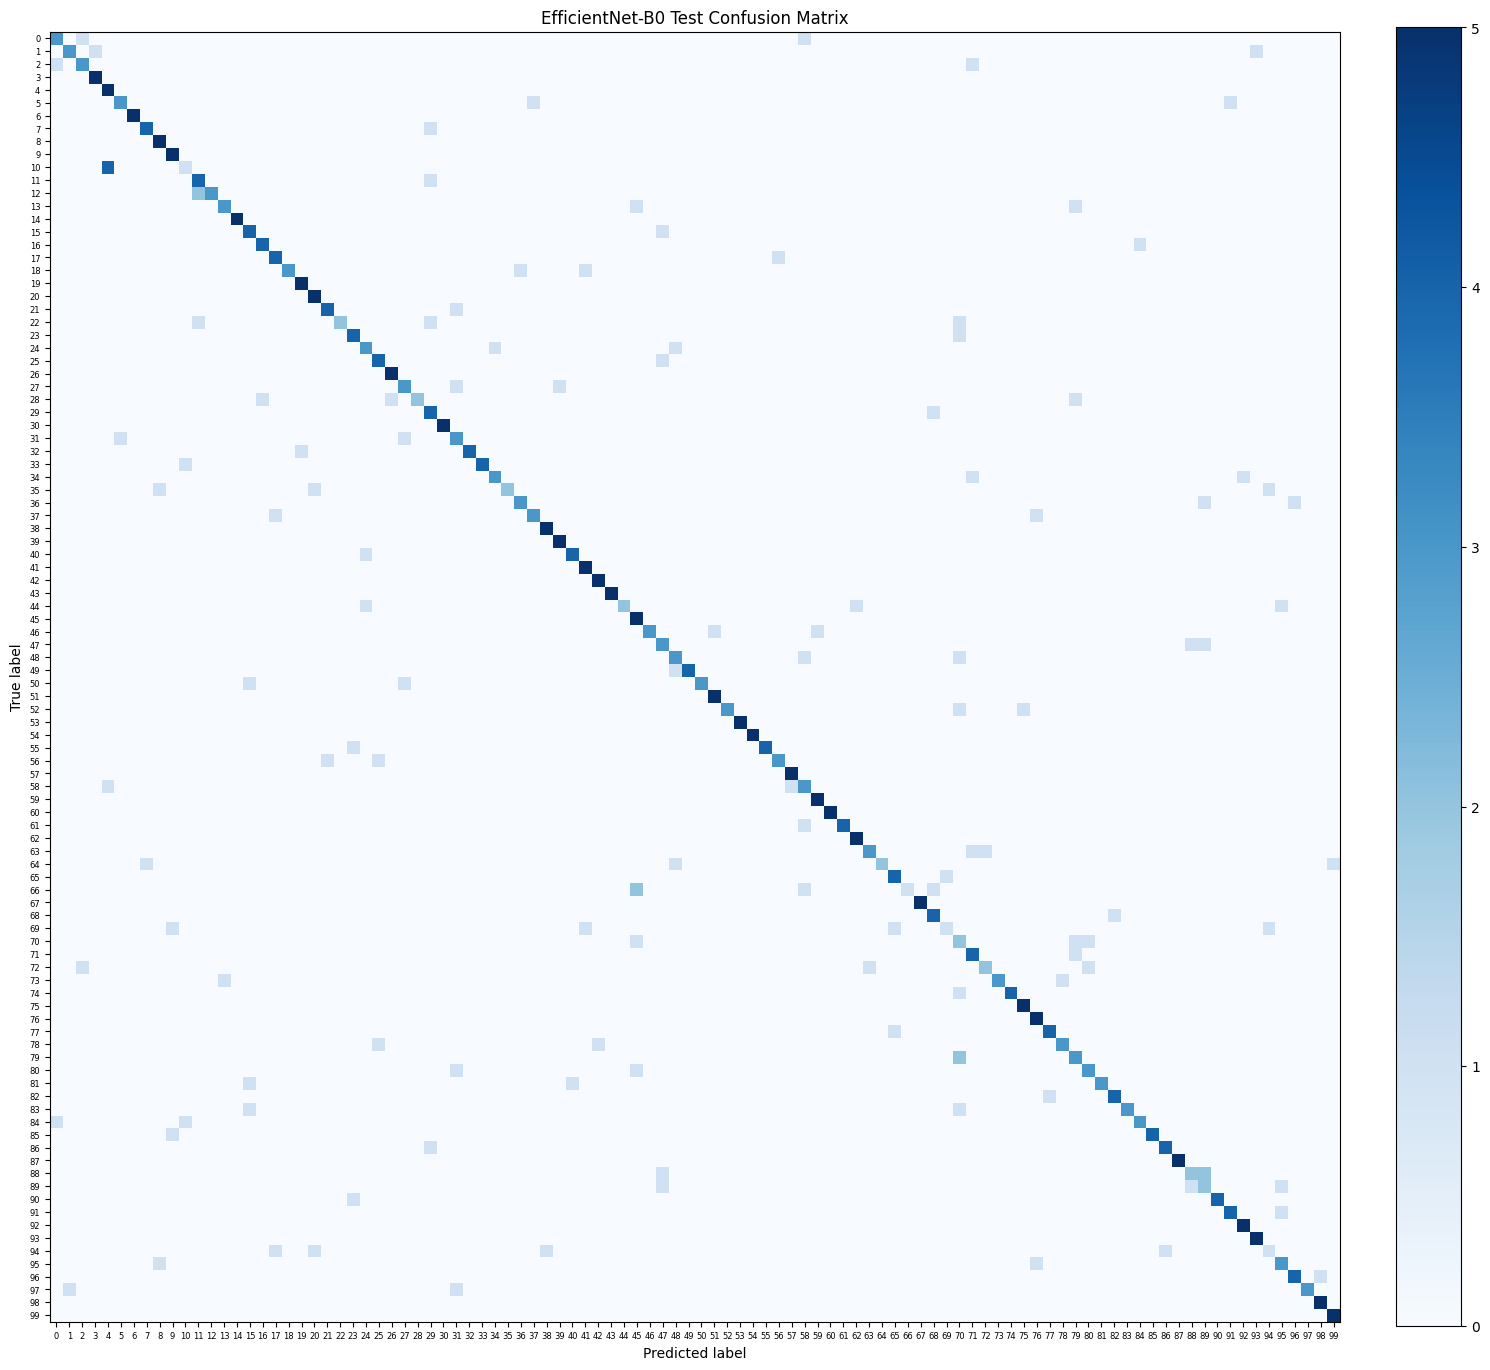

In [9]:
confusion = confusion_matrix(true_labels, predicted_labels, labels=list(range(num_classes)))
figure_size = max(10, num_classes * 0.15)
fig, axis = plt.subplots(figsize=(figure_size, figure_size))
image = axis.imshow(confusion, interpolation='nearest', cmap='Blues')
fig.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
axis.set_title('EfficientNet-B0 Test Confusion Matrix')
axis.set_xlabel('Predicted label')
axis.set_ylabel('True label')
axis.set_xticks(range(num_classes))
axis.set_yticks(range(num_classes))
axis.tick_params(axis='both', labelsize=6)
fig.tight_layout()
plt.show()

In [10]:
METRICS_PATH.write_text(json.dumps(metrics, indent=2), encoding='utf-8')
fig.savefig(CONFUSION_MATRIX_PATH, dpi=150)
plt.close(fig)
print(f'Saved metrics to {METRICS_PATH}.')
print(f'Saved confusion matrix to {CONFUSION_MATRIX_PATH}.')

Saved metrics to c:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water\results\efficientnet_b0_test_metrics.json.
Saved confusion matrix to c:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water\results\efficientnet_b0_confusion_matrix.png.


## Conclusion

The trained EfficientNet-B0 achieved the actual test metrics shown above on the held-out test set. Top-5 accuracy is higher than top-1 accuracy, indicating that the correct cultivar is often among the model's five highest-scoring predictions.